# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(spectral mode: WHACS partitions `0`–`3` per goal, wavespectra linear sum).

Bulk output is configured in the case JSON → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import os
import time

os.environ["OMP_NUM_THREADS"] = "8"  # avoid oversubscription when using dask

import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils import validation as val
from utils import metamodel as mm

## Configuration

In [2]:
period = slice("2010", "2015")
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = None  # e.g. "10m", "buoy", or a list of explicit site ids

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"])
    / f"Dynamic_Cases_{offshore_name}_2010-2015.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : slice('2010', '2015', None)
mda_n        : 450
sites        : None
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2010-2015.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 1201


## 2 · Reconstruct metamodel (bulk)

In [4]:
t0 = time.perf_counter()
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    workers=8,
    save_spectra=False,  # bulk-vs-dynamic validation never reads spectra —
    # the case JSON defaults save_spectra=true (for notebook 11), which was
    # needlessly computing and accumulating a full (time, sites, freq, dir)
    # array per batch here, ~1000x bigger than the bulk stats actually
    # used below, and is the real driver of memory growth if this is run
    # at full site-count scale.
)
reconstruct_seconds = time.perf_counter() - t0
print(
    f"Reconstruction took {reconstruct_seconds:.2f}s for {metamodel.sizes.get('sites', '?')} sites"
)
metamodel

Reconstruction took 5.10s for 1201 sites


<xarray.Dataset> Size: 2GB
Dimensions:         (time: 52584, sites: 1201)
Coordinates:
  * time            (time) datetime64[ns] 421kB 2010-01-01 ... 2015-12-31T23:...
  * sites           (sites) <U27 130kB '10m_0' ... 'buoy_ZandmoterBoeiNoord'
    site_source     (sites) <U7 34kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 24kB '10m' '10m' '10m' ... 'waves' 'waves'
    site_depth      (sites) float64 10kB -10.0 -10.0 -10.0 -10.0 ... nan nan nan
    site_longitude  (sites) float64 10kB 6.775 6.77 6.654 ... 4.996 6.367 4.158
    site_latitude   (sites) float64 10kB 53.64 53.64 53.68 ... 53.32 53.62 52.05
Data variables:
    hs              (time, sites) float64 505MB 1.581 1.681 ... 0.8507 1.206
    tp              (time, sites) float32 253MB 5.389 5.391 ... 6.864 6.455
    dir             (time, sites) float64 505MB 32.61 33.62 ... 259.9 264.2
    spr             (time, sites) float64 505MB 42.2 38.35 27.89 ... 30.74 14.15

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 337MB
Dimensions:         (time: 17520, sites: 1201)
Coordinates:
  * time            (time) datetime64[ns] 140kB 2010-01-01 ... 2015-12-31T23:...
  * sites           (sites) <U27 130kB '10m_0' ... 'buoy_ZandmoterBoeiNoord'
    site_source     (sites) <U7 34kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 24kB '10m' '10m' '10m' ... 'waves' 'waves'
    site_depth      (sites) float64 10kB -10.0 -10.0 -10.0 -10.0 ... nan nan nan
    site_longitude  (sites) float64 10kB 6.775 6.77 6.654 ... 4.996 6.367 4.158
    site_latitude   (sites) float64 10kB 53.64 53.64 53.68 ... 53.32 53.62 52.05
Data variables:
    hs              (time, sites) float32 84MB 1.458 1.626 1.437 ... 1.191 1.071
    tp              (time, sites) float32 84MB 6.289 6.289 6.289 ... 6.908 6.908
    dir             (time, sites) float32 84MB 48.26 40.46 11.42 ... 252.5 265.5
    spr             (time, sites) float32 84MB 39.66 37.2 24.39 ... 39.37 15.04
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.3 of Aug 25 2026 19:35:26 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
metamodel = xr.concat(
    [
        metamodel.sel(time="2010"),
        metamodel.sel(time="2015"),
    ],
    dim="time",
)
metamodel

<xarray.Dataset> Size: 590MB
Dimensions:         (time: 17520, sites: 1201)
Coordinates:
  * time            (time) datetime64[ns] 140kB 2010-01-01 ... 2015-12-31T23:...
  * sites           (sites) <U27 130kB '10m_0' ... 'buoy_ZandmoterBoeiNoord'
    site_source     (sites) <U7 34kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 24kB '10m' '10m' '10m' ... 'waves' 'waves'
    site_depth      (sites) float64 10kB -10.0 -10.0 -10.0 -10.0 ... nan nan nan
    site_longitude  (sites) float64 10kB 6.775 6.77 6.654 ... 4.996 6.367 4.158
    site_latitude   (sites) float64 10kB 53.64 53.64 53.68 ... 53.32 53.62 52.05
Data variables:
    hs              (time, sites) float64 168MB 1.581 1.681 ... 0.8507 1.206
    tp              (time, sites) float32 84MB 5.389 5.391 5.389 ... 6.864 6.455
    dir             (time, sites) float64 168MB 32.61 33.62 ... 259.9 264.2
    spr             (time, sites) float64 168MB 42.2 38.35 27.89 ... 30.74 14.15

In [7]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    reference=dynamic,
    estimate=metamodel,
    variables=variables,
    reference_label="Dynamic SnapWave",
    estimate_label="Linear summation",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,7936501,0.140648,0.374224,0.744759,Linear summation,Dynamic SnapWave
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,7936505,0.033069,1.372172,0.676548,Linear summation,Dynamic SnapWave
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,7936560,0.818611,23.782752,0.820441,Linear summation,Dynamic SnapWave
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,7936560,1.945694,7.485989,0.428414,Linear summation,Dynamic SnapWave
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,5641434,0.072599,0.228258,0.878550,Linear summation,Dynamic SnapWave
5,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,tp,Tp,5641415,-0.109479,1.456593,0.614710,Linear summation,Dynamic SnapWave
6,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,dir,Dir,5641440,1.344293,25.597251,0.802531,Linear summation,Dynamic SnapWave
7,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,spr,Spr,5641440,1.245378,7.206888,0.428783,Linear summation,Dynamic SnapWave
8,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,hs,Hs,7025515,0.021524,0.145598,0.954019,Linear summation,Dynamic SnapWave
9,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,tp,Tp,7025503,-0.124221,1.446177,0.618562,Linear summation,Dynamic SnapWave


## 5 · Save metrics

In [8]:
period = "2010, 2015"
period

'2010, 2015'

In [9]:
metrics_out = result.metrics.copy()
metrics_out.insert(0, "period", period)
metrics_out.insert(1, "mda_candidate", mda_n)
metrics_out.insert(2, "offshore_name", offshore_name)
metrics_out["n_sites"] = int(metamodel.sizes["sites"])
# Wall time for mm.reconstruct() above — near-zero if these sites/period
# were already cached from a previous run, not a fresh-simulation cost.
metrics_out["reconstruct_seconds"] = reconstruct_seconds

out_path = val.metamodel_validation_path(period)
out_path.parent.mkdir(parents=True, exist_ok=True)
metrics_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/metamodel_validation/linear_summation_2010-2015.csv


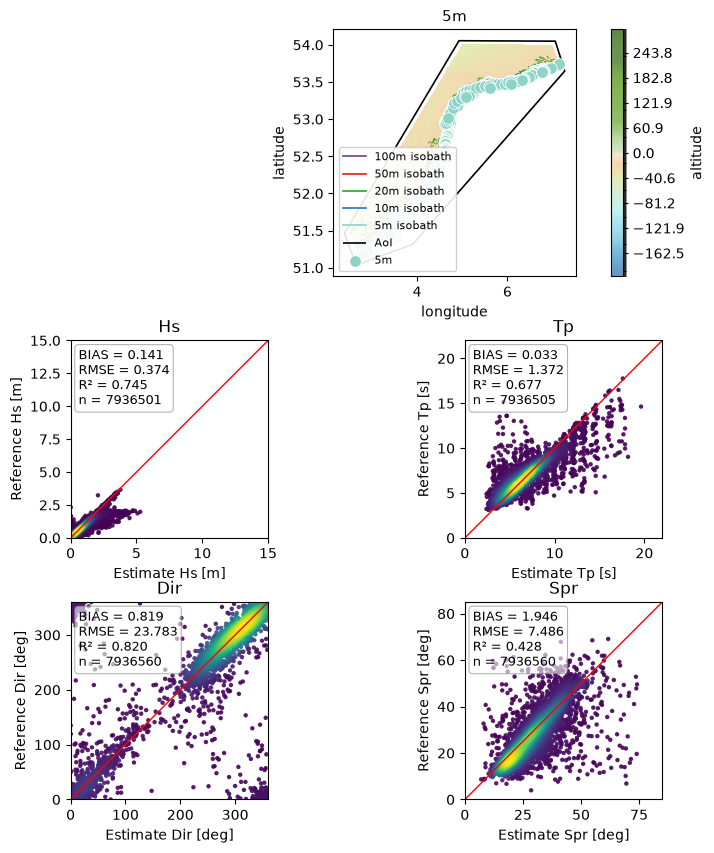

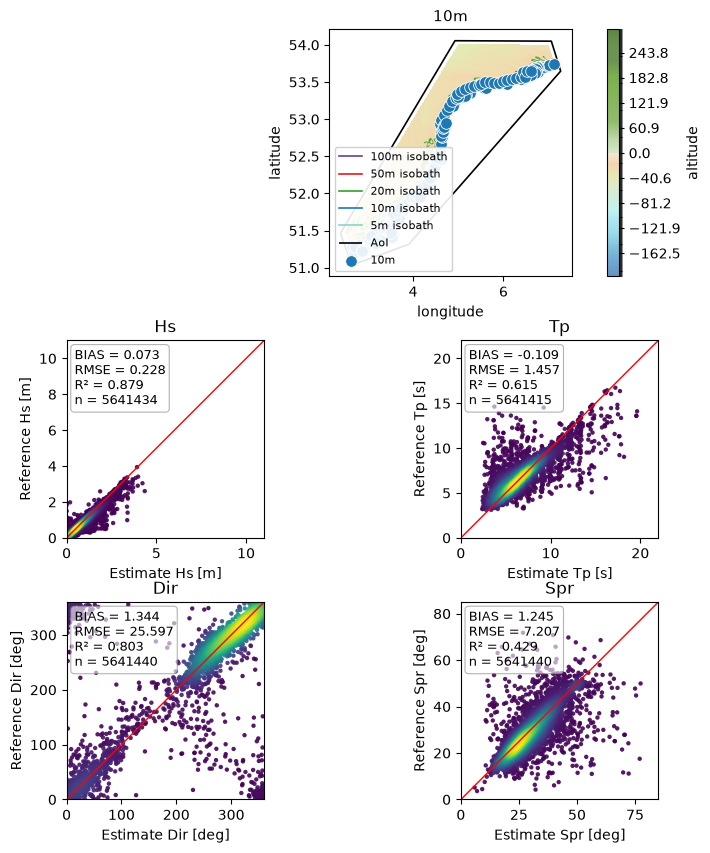

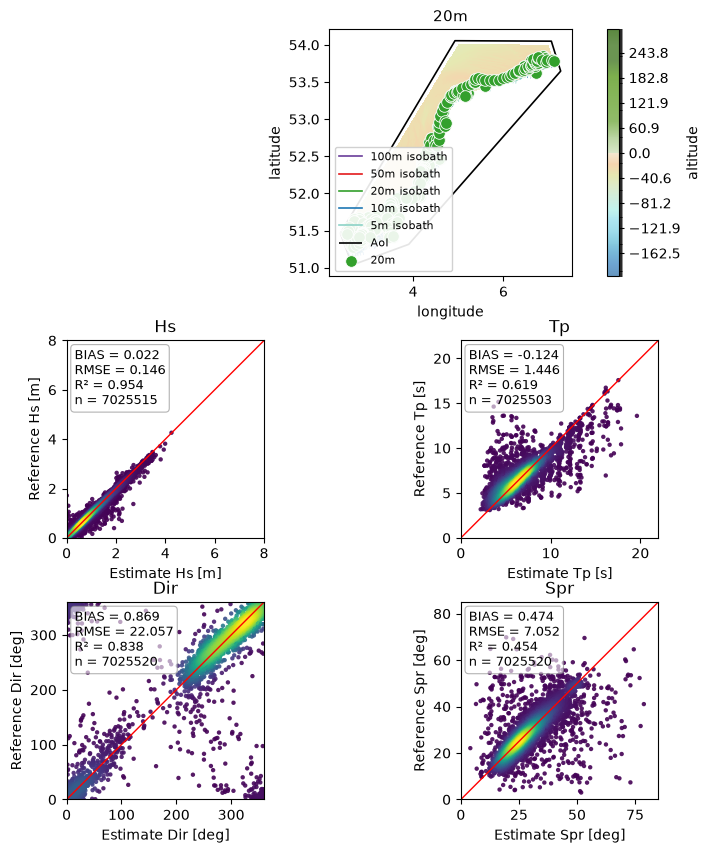

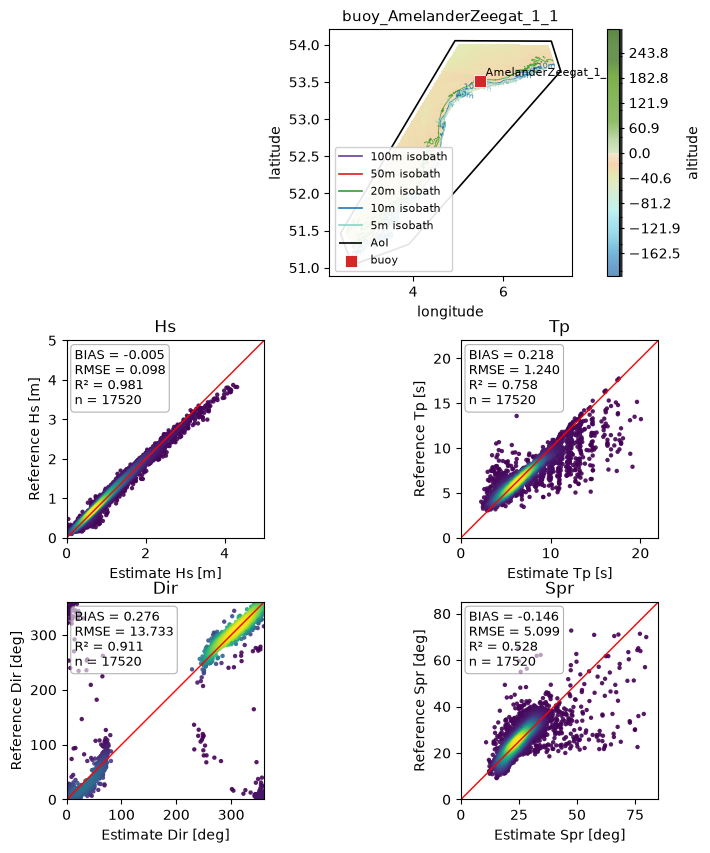

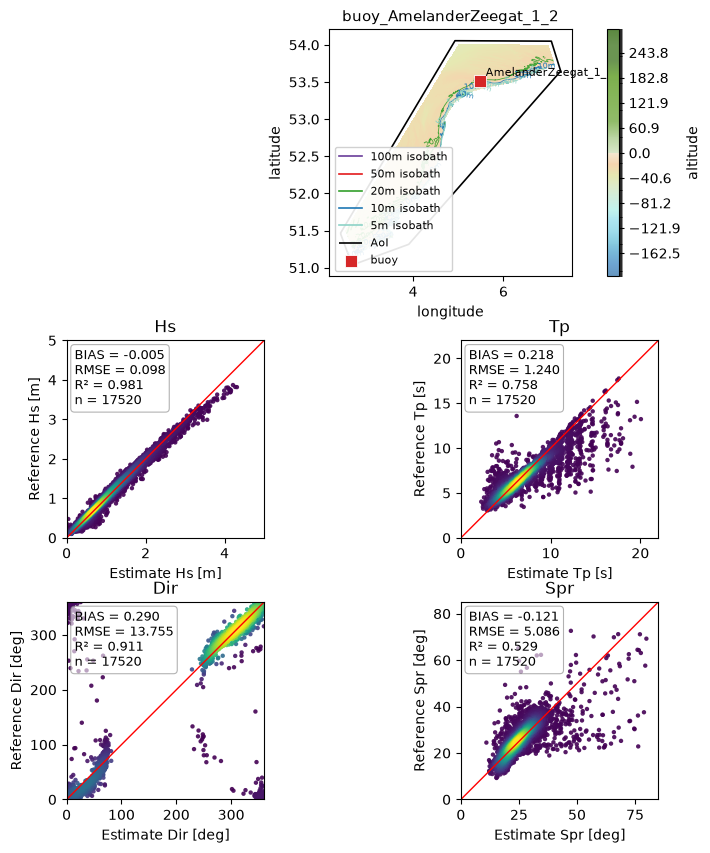

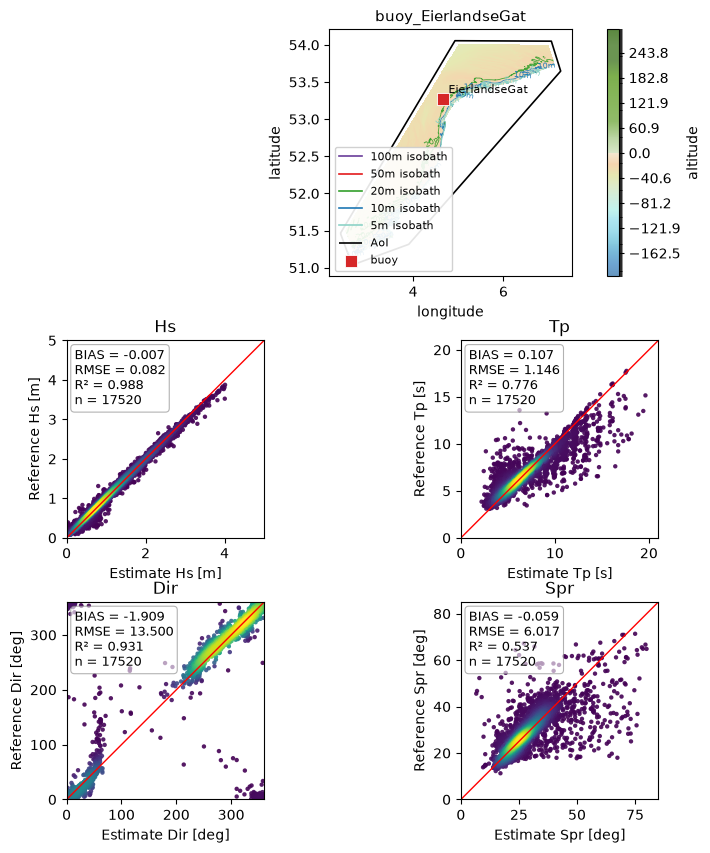

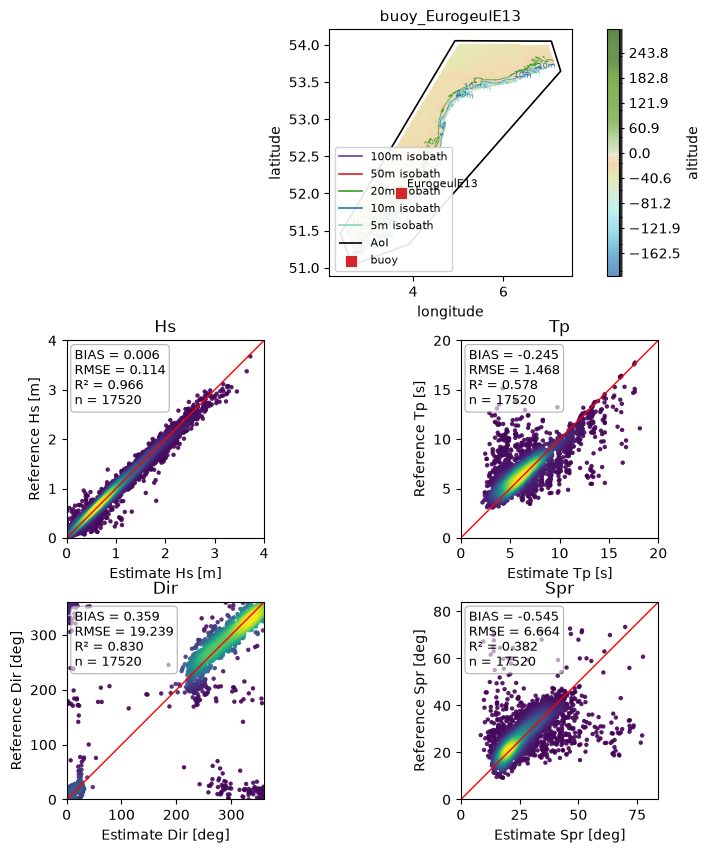

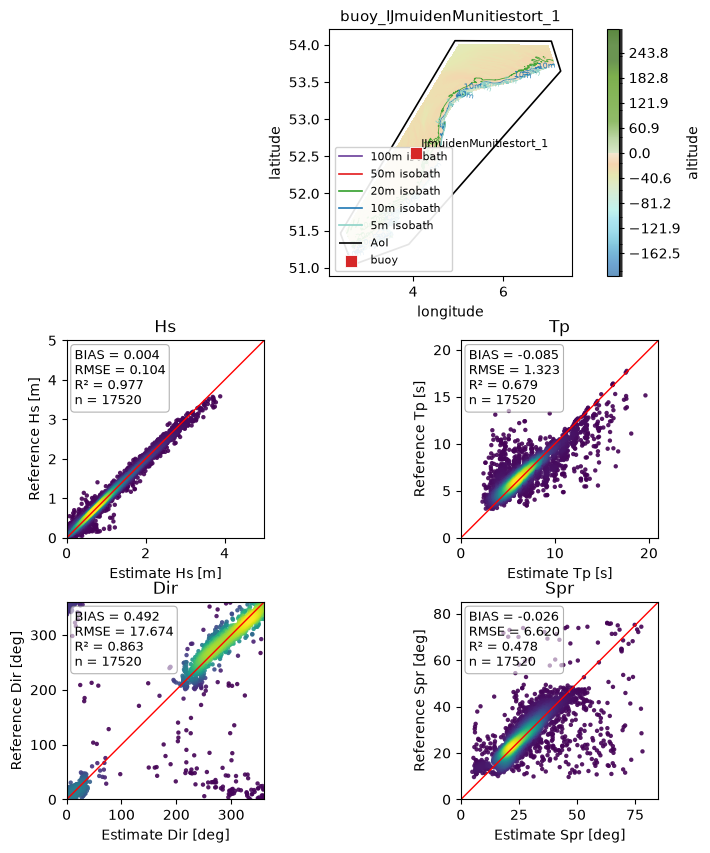

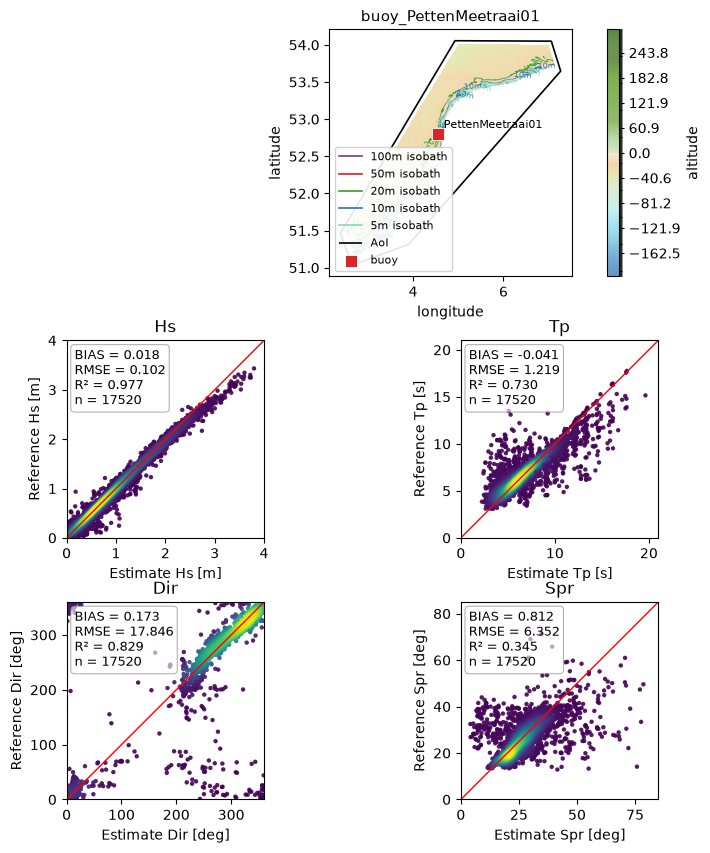

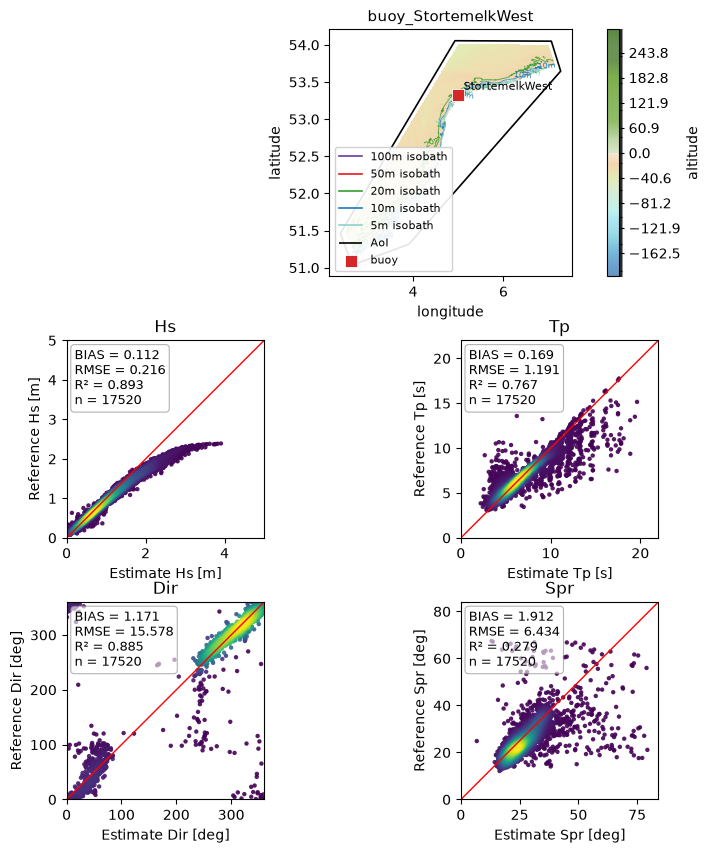

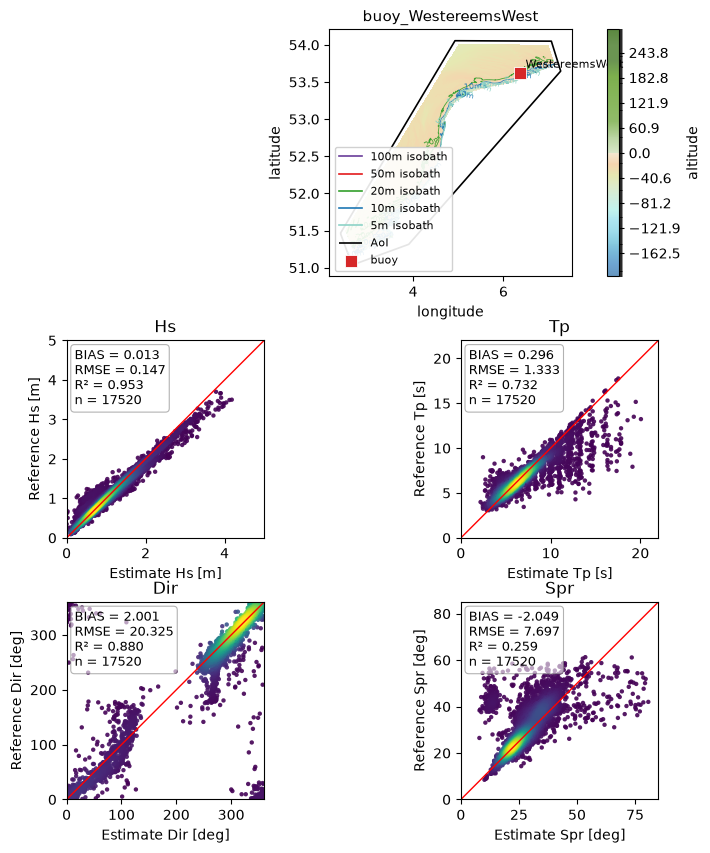

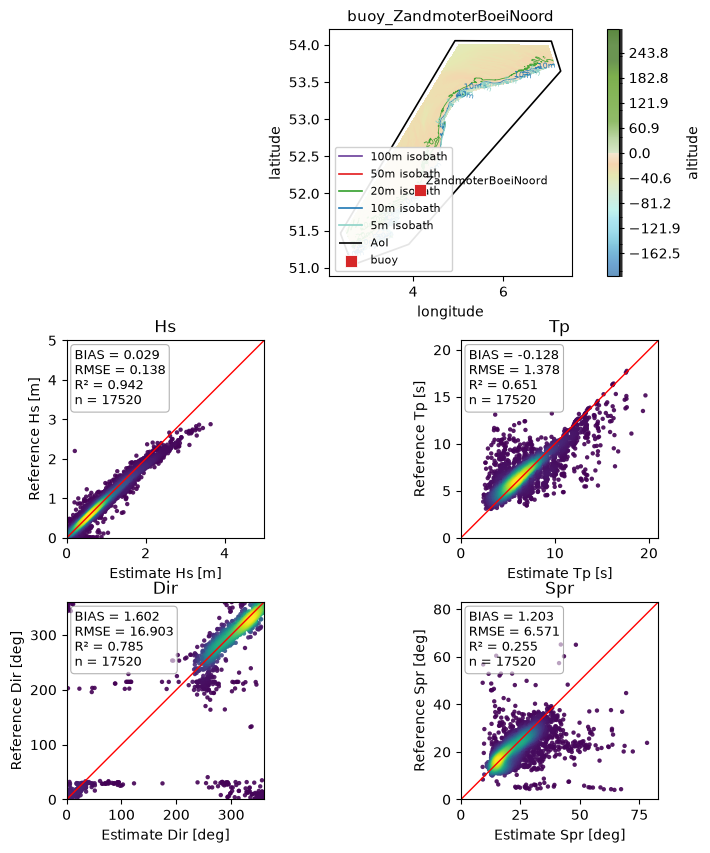

In [10]:
result.plot_all(variables=variables)
plt.show()